In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
data_path = "../data/processed/validated_historical_metrics.csv"

df = pd.read_csv(data_path)

df["timestamp"] = pd.to_datetime(df["timestamp"])

print("Data loaded successfully!")
print("Shape:", df.shape)

df.head()

Data loaded successfully!
Shape: (12096, 8)


,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate
0,2014-02-14 14:27:00,SERVER-01,51.846,63.433712,0.1,0.239985,72.239873,96.050844
1,2014-02-14 14:32:00,SERVER-01,44.508,60.856538,0.1,3.055105,62.801950,85.923800
2,2014-02-14 14:37:00,SERVER-01,41.244,59.360727,0.1,0.274083,62.723795,79.731062
3,2014-02-14 14:42:00,SERVER-01,48.568,62.804124,0.1,0.227875,54.152422,81.115477
4,2014-02-14 14:47:00,SERVER-01,46.714,60.620752,0.1,0.234489,61.861019,84.759392


In [4]:
features = [
    "cpu_usage",
    "memory_usage",
    "disk_usage",
    "network_traffic",
    "response_time",
    "request_rate"
]

X = df[features]

print("Features prepared!")
print("Feature shape:", X.shape)

Features prepared!
Feature shape: (12096, 6)


In [5]:
scaler = joblib.load("../models/scaler.joblib")

X_scaled = scaler.transform(X)

print("Scaling completed!")
print("Scaled shape:", X_scaled.shape)


Scaling completed!
Scaled shape: (12096, 6)


In [6]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X_scaled)

print("Isolation Forest model trained successfully!")

Isolation Forest model trained successfully!


In [7]:
df["anomaly_score"] = model.decision_function(X_scaled)
df["anomaly"] = model.predict(X_scaled)

# Convert: -1 = anomaly, 1 = normal
df["status"] = df["anomaly"].map({
    1: "NORMAL",
    -1: "ANOMALY"
})

print(df["status"].value_counts())

status
NORMAL     11491
ANOMALY      605
Name: count, dtype: int64


In [8]:
anomalies = df[df["status"] == "ANOMALY"]

print("Total anomalies:", len(anomalies))
anomalies.head(10)

Total anomalies: 605


,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate,anomaly_score,anomaly,status
1173,2014-02-18 16:12:00,SERVER-01,52.348,62.999405,29.935932,3.087187,71.748789,95.324685,-0.005194,-1,ANOMALY
1271,2014-02-19 00:22:00,SERVER-01,62.056,64.901163,2.379684,3.104343,71.080197,106.720601,-0.009864,-1,ANOMALY
1640,2014-02-20 07:07:00,SERVER-01,43.334,60.389392,175.441742,132.367134,64.705038,79.080170,-0.069433,-1,ANOMALY
1643,2014-02-20 07:22:00,SERVER-01,43.404,58.609258,0.100000,233.770370,63.963862,83.229214,-0.007894,-1,ANOMALY
1644,2014-02-20 07:27:00,SERVER-01,42.206,58.584155,0.100000,60.300159,63.206323,74.466717,-0.002234,-1,ANOMALY
2635,2014-02-23 18:02:00,SERVER-01,42.052,61.146174,407.249451,0.202392,54.666238,80.630599,-0.004803,-1,ANOMALY
2649,2014-02-23 19:12:00,SERVER-01,38.874,61.657384,428.187370,0.203422,57.833172,76.417823,-0.000512,-1,ANOMALY
2677,2014-02-23 21:32:00,SERVER-01,43.602,61.637743,408.066750,0.195200,69.530577,79.398916,-0.009824,-1,ANOMALY
2919,2014-02-24 17:42:00,SERVER-01,42.606,59.521622,432.242393,0.194541,68.201697,80.846110,-0.004151,-1,ANOMALY
3199,2014-02-25 17:02:00,SERVER-01,36.824,56.892046,430.749893,0.205091,75.703733,72.004832,-0.017975,-1,ANOMALY


In [9]:
anomaly_by_server = (
    anomalies["server_id"]
    .value_counts()
    .reset_index()
)

anomaly_by_server.columns = ["server_id", "anomaly_count"]

print("Anomalies by server:")
anomaly_by_server

Anomalies by server:


,server_id,anomaly_count
0,SERVER-02,511
1,SERVER-03,80
2,SERVER-01,14


In [10]:
output_path = "../results/predictions/anomaly_predictions.csv"

df.to_csv(output_path, index=False)

print("Anomaly predictions saved successfully!")
print("Saved to:", output_path)

Anomaly predictions saved successfully!
Saved to: ../results/predictions/anomaly_predictions.csv


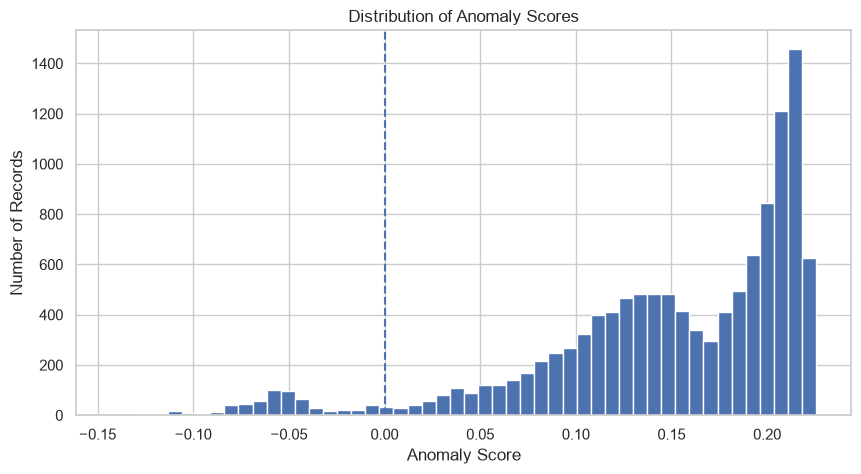

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(df["anomaly_score"], bins=50)

plt.axvline(0, linestyle="--")

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Records")
plt.title("Distribution of Anomaly Scores")

plt.show()

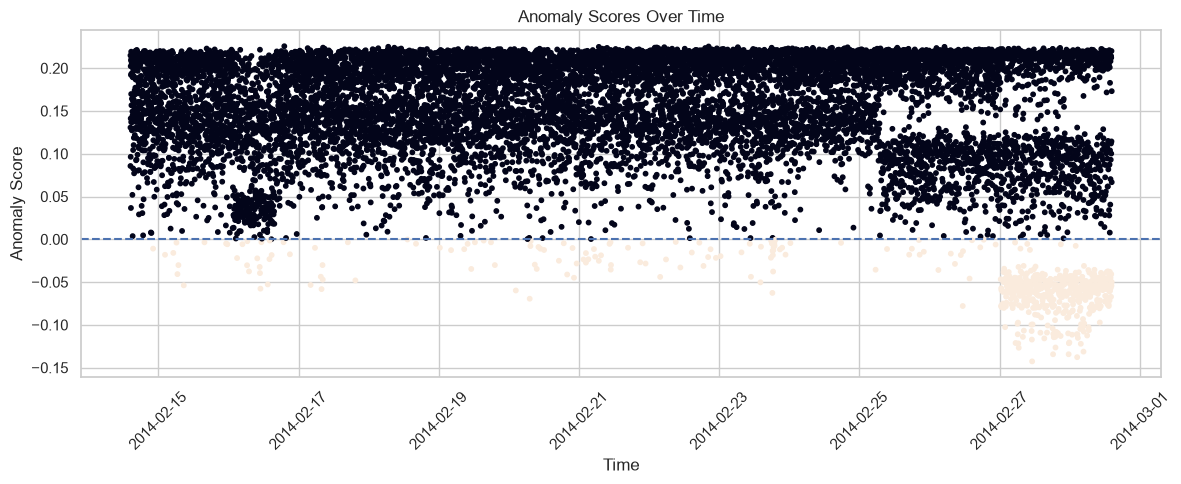

In [12]:
plt.figure(figsize=(12, 5))

plt.scatter(
    df["timestamp"],
    df["anomaly_score"],
    c=(df["status"] == "ANOMALY"),
    s=10
)

plt.axhline(0, linestyle="--")

plt.xlabel("Time")
plt.ylabel("Anomaly Score")
plt.title("Anomaly Scores Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
anomalies = df[df["status"] == "ANOMALY"]

print("Total anomalies:", len(anomalies))

anomalies[[
    "timestamp",
    "server_id",
    "cpu_usage",
    "memory_usage",
    "disk_usage",
    "network_traffic",
    "response_time",
    "request_rate",
    "anomaly_score"
]].head(20)

Total anomalies: 605


,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate,anomaly_score
1173,2014-02-18 16:12:00,SERVER-01,52.348,62.999405,29.935932,3.087187,71.748789,95.324685,-0.005194
1271,2014-02-19 00:22:00,SERVER-01,62.056,64.901163,2.379684,3.104343,71.080197,106.720601,-0.009864
1640,2014-02-20 07:07:00,SERVER-01,43.334,60.389392,175.441742,132.367134,64.705038,79.080170,-0.069433
1643,2014-02-20 07:22:00,SERVER-01,43.404,58.609258,0.100000,233.770370,63.963862,83.229214,-0.007894
1644,2014-02-20 07:27:00,SERVER-01,42.206,58.584155,0.100000,60.300159,63.206323,74.466717,-0.002234
2635,2014-02-23 18:02:00,SERVER-01,42.052,61.146174,407.249451,0.202392,54.666238,80.630599,-0.004803
2649,2014-02-23 19:12:00,SERVER-01,38.874,61.657384,428.187370,0.203422,57.833172,76.417823,-0.000512
2677,2014-02-23 21:32:00,SERVER-01,43.602,61.637743,408.066750,0.195200,69.530577,79.398916,-0.009824
2919,2014-02-24 17:42:00,SERVER-01,42.606,59.521622,432.242393,0.194541,68.201697,80.846110,-0.004151
3199,2014-02-25 17:02:00,SERVER-01,36.824,56.892046,430.749893,0.205091,75.703733,72.004832,-0.017975


In [14]:
output_path = "../results/predictions/anomaly_predictions.csv"

df.to_csv(output_path, index=False)

print("Anomaly predictions saved successfully!")
print("Location:", output_path)

Anomaly predictions saved successfully!
Location: ../results/predictions/anomaly_predictions.csv


In [15]:
print("===== ANOMALY DETECTION SUMMARY =====")

print("Total records:", len(df))
print("Normal records:", (df["status"] == "NORMAL").sum())
print("Anomalous records:", (df["status"] == "ANOMALY").sum())

anomaly_percentage = (df["status"] == "ANOMALY").mean() * 100

print("Anomaly percentage:", round(anomaly_percentage, 2), "%")

===== ANOMALY DETECTION SUMMARY =====
Total records: 12096
Normal records: 11491
Anomalous records: 605
Anomaly percentage: 5.0 %


In [16]:
server_anomalies = df[df["status"] == "ANOMALY"].groupby("server_id").size()

print("===== ANOMALIES BY SERVER =====")
print(server_anomalies)

===== ANOMALIES BY SERVER =====
server_id
SERVER-01     14
SERVER-02    511
SERVER-03     80
dtype: int64


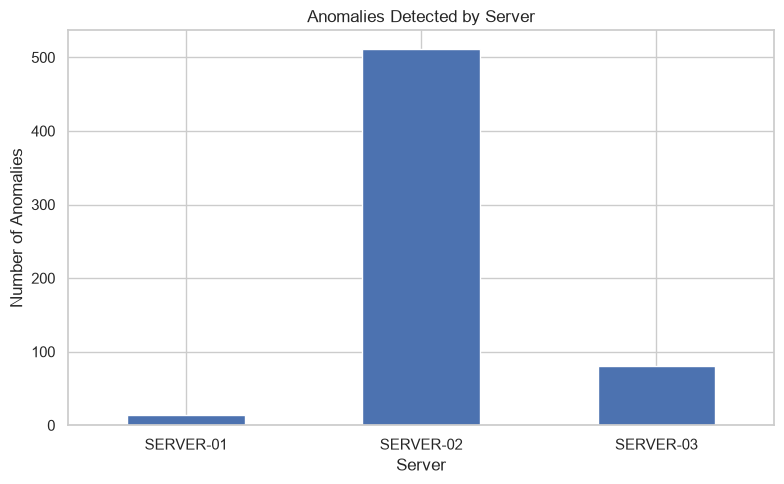

In [17]:
plt.figure(figsize=(8, 5))

server_anomalies.plot(kind="bar")

plt.xlabel("Server")
plt.ylabel("Number of Anomalies")
plt.title("Anomalies Detected by Server")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
top_anomalies = df[df["status"] == "ANOMALY"].sort_values(
    "anomaly_score"
).head(20)

top_anomalies[[
    "timestamp",
    "server_id",
    "cpu_usage",
    "memory_usage",
    "disk_usage",
    "network_traffic",
    "response_time",
    "request_rate",
    "anomaly_score",
    "status"
]]

,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate,anomaly_score,status
7736,2014-02-27 11:07:00,SERVER-02,98.474,83.805631,500.000000,0.100000,189.376968,164.111190,-0.142676,ANOMALY
7921,2014-02-28 02:32:00,SERVER-02,98.990,84.251963,500.000000,0.100000,201.725973,167.890728,-0.137753,ANOMALY
7886,2014-02-27 23:37:00,SERVER-02,99.112,83.130786,500.000000,0.100000,203.012267,164.596477,-0.134326,ANOMALY
7822,2014-02-27 18:17:00,SERVER-02,99.390,83.790163,500.000000,0.100000,207.978382,168.708141,-0.134326,ANOMALY
7947,2014-02-28 04:42:00,SERVER-02,99.274,82.831361,397.894859,0.100000,206.127250,170.595240,-0.131243,ANOMALY
7681,2014-02-27 06:32:00,SERVER-02,98.522,86.434019,110.476494,0.100000,202.053647,159.663184,-0.126737,ANOMALY
7832,2014-02-27 19:07:00,SERVER-02,99.366,83.369200,500.000000,0.100000,208.895277,162.393851,-0.126455,ANOMALY
7936,2014-02-28 03:47:00,SERVER-02,99.106,83.574031,500.000000,0.100000,209.341654,163.119486,-0.122120,ANOMALY
7679,2014-02-27 06:22:00,SERVER-02,99.250,83.848351,457.405090,0.100000,212.859749,163.368663,-0.121641,ANOMALY
7887,2014-02-27 23:42:00,SERVER-02,97.982,85.100095,82.391357,0.100000,197.589908,161.260343,-0.121441,ANOMALY


In [19]:
model_path = "../models/isolation_forest.joblib"

joblib.dump(model, model_path)

print("Isolation Forest model saved successfully!")
print("Location:", model_path)

Isolation Forest model saved successfully!
Location: ../models/isolation_forest.joblib


In [20]:
server_summary = df.groupby("server_id").agg(
    total_records=("server_id", "size"),
    anomalies=("status", lambda x: (x == "ANOMALY").sum())
)

server_summary["normal_records"] = (
    server_summary["total_records"] - server_summary["anomalies"]
)

server_summary["anomaly_percentage"] = (
    server_summary["anomalies"] /
    server_summary["total_records"] * 100
).round(2)

server_summary

,total_records,anomalies,normal_records,anomaly_percentage
server_id,,,,
SERVER-01,4032,14,4018,0.35
SERVER-02,4032,511,3521,12.67
SERVER-03,4032,80,3952,1.98


In [21]:
summary_path = "../results/reports/server_anomaly_summary.csv"

server_summary.to_csv(summary_path)

print("Server anomaly summary saved successfully!")
print("Location:", summary_path)

Server anomaly summary saved successfully!
Location: ../results/reports/server_anomaly_summary.csv


In [22]:
comparison = df.groupby("status")[
    [
        "cpu_usage",
        "memory_usage",
        "disk_usage",
        "network_traffic",
        "response_time",
        "request_rate"
    ]
].mean().round(2)

print("===== NORMAL vs ANOMALY METRIC COMPARISON =====")
comparison

===== NORMAL vs ANOMALY METRIC COMPARISON =====


,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate
status,,,,,,
ANOMALY,79.81,75.93,61.28,1.81,172.89,166.14
NORMAL,28.15,52.66,13.71,2.35,55.51,67.73


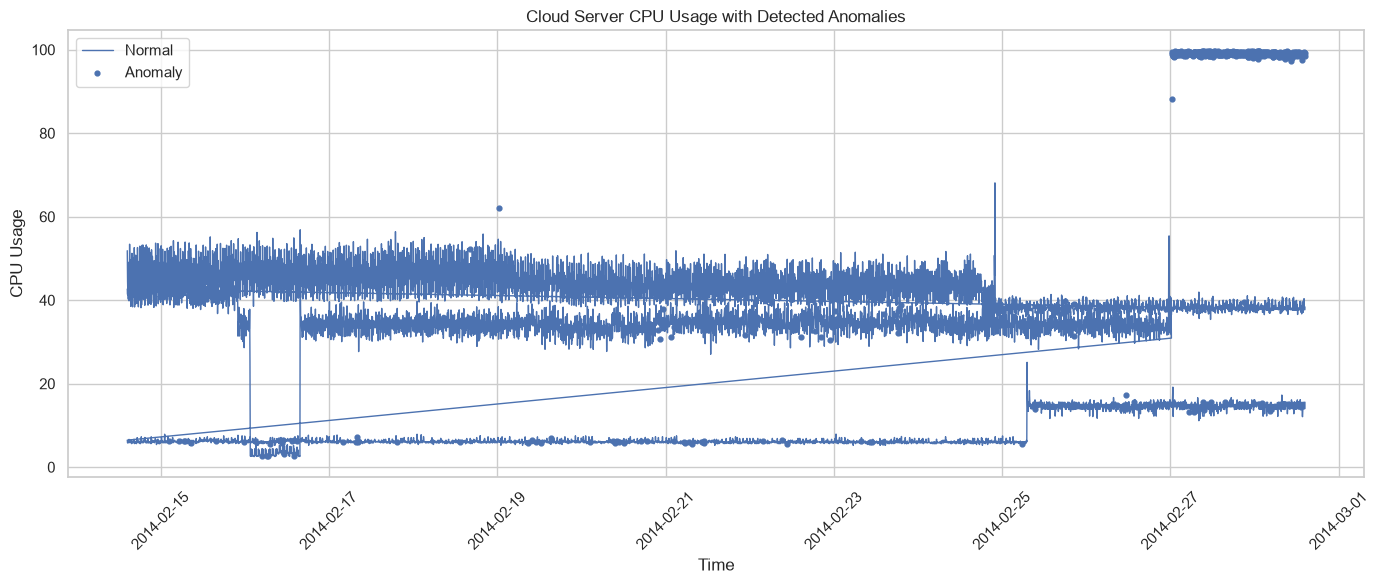

In [23]:
plt.figure(figsize=(14, 6))

normal = df[df["status"] == "NORMAL"]
anomaly = df[df["status"] == "ANOMALY"]

plt.plot(
    normal["timestamp"],
    normal["cpu_usage"],
    linewidth=1,
    label="Normal"
)

plt.scatter(
    anomaly["timestamp"],
    anomaly["cpu_usage"],
    s=12,
    label="Anomaly"
)

plt.xlabel("Time")
plt.ylabel("CPU Usage")
plt.title("Cloud Server CPU Usage with Detected Anomalies")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
print("Columns containing 'label' or 'anomaly':")

for column in df.columns:
    if "label" in column.lower() or "anomaly" in column.lower():
        print(column)

Columns containing 'label' or 'anomaly':
anomaly_score
anomaly


In [25]:
original_columns = [
    "timestamp",
    "server_id",
    "cpu_usage",
    "memory_usage",
    "disk_usage",
    "network_traffic",
    "response_time",
    "request_rate"
]

print("Original dataset columns:")
print(original_columns)

print("\nNo ground-truth anomaly label is present.")
print("Evaluation will therefore use unsupervised analysis.")

Original dataset columns:
['timestamp', 'server_id', 'cpu_usage', 'memory_usage', 'disk_usage', 'network_traffic', 'response_time', 'request_rate']

No ground-truth anomaly label is present.
Evaluation will therefore use unsupervised analysis.


In [26]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

lof_predictions = lof.fit_predict(X_scaled)

df["lof_prediction"] = lof_predictions
df["lof_status"] = df["lof_prediction"].map({
    1: "NORMAL",
    -1: "ANOMALY"
})

print("===== LOF RESULTS =====")
print(df["lof_status"].value_counts())

===== LOF RESULTS =====
lof_status
NORMAL     11491
ANOMALY      605
Name: count, dtype: int64


In [27]:
comparison = pd.crosstab(
    df["status"],
    df["lof_status"],
    rownames=["Isolation Forest"],
    colnames=["LOF"]
)

print("===== ISOLATION FOREST vs LOF =====")
comparison

===== ISOLATION FOREST vs LOF =====


LOF,ANOMALY,NORMAL
Isolation Forest,,
ANOMALY,86,519
NORMAL,519,10972


In [28]:
both_anomalies = df[
    (df["status"] == "ANOMALY") &
    (df["lof_status"] == "ANOMALY")
]

print("===== ANOMALIES DETECTED BY BOTH MODELS =====")
print("Total:", len(both_anomalies))

both_anomalies[[
    "timestamp",
    "server_id",
    "cpu_usage",
    "memory_usage",
    "disk_usage",
    "network_traffic",
    "response_time",
    "request_rate",
    "anomaly_score",
    "status",
    "lof_status"
]].head(20)

===== ANOMALIES DETECTED BY BOTH MODELS =====
Total: 86


,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate,anomaly_score,status,lof_status
1173,2014-02-18 16:12:00,SERVER-01,52.348,62.999405,29.935932,3.087187,71.748789,95.324685,-0.005194,ANOMALY,ANOMALY
1271,2014-02-19 00:22:00,SERVER-01,62.056,64.901163,2.379684,3.104343,71.080197,106.720601,-0.009864,ANOMALY,ANOMALY
1640,2014-02-20 07:07:00,SERVER-01,43.334,60.389392,175.441742,132.367134,64.705038,79.080170,-0.069433,ANOMALY,ANOMALY
1643,2014-02-20 07:22:00,SERVER-01,43.404,58.609258,0.100000,233.770370,63.963862,83.229214,-0.007894,ANOMALY,ANOMALY
1644,2014-02-20 07:27:00,SERVER-01,42.206,58.584155,0.100000,60.300159,63.206323,74.466717,-0.002234,ANOMALY,ANOMALY
4492,2014-02-16 04:47:00,SERVER-02,2.662,41.294613,0.100000,0.100000,31.543944,20.129356,-0.005751,ANOMALY,ANOMALY
4511,2014-02-16 06:22:00,SERVER-02,2.630,44.088835,360.630989,0.100000,42.370544,11.252961,-0.030323,ANOMALY,ANOMALY
4512,2014-02-16 06:27:00,SERVER-02,2.652,41.273717,85.606289,0.100000,36.951876,18.165301,-0.002248,ANOMALY,ANOMALY
4566,2014-02-16 10:57:00,SERVER-02,3.686,40.487437,434.488297,0.100000,47.168428,19.961160,-0.057673,ANOMALY,ANOMALY
4570,2014-02-16 11:17:00,SERVER-02,3.262,40.742926,0.100000,0.100000,32.661852,20.078344,-0.003423,ANOMALY,ANOMALY


In [29]:
def classify_anomaly(row):
    if row["status"] == "ANOMALY" and row["lof_status"] == "ANOMALY":
        return "HIGH_CONFIDENCE_ANOMALY"
    elif row["status"] == "ANOMALY" or row["lof_status"] == "ANOMALY":
        return "POSSIBLE_ANOMALY"
    else:
        return "NORMAL"

df["final_status"] = df.apply(classify_anomaly, axis=1)

print("===== FINAL ENSEMBLE RESULTS =====")
print(df["final_status"].value_counts())

===== FINAL ENSEMBLE RESULTS =====
final_status
NORMAL                     10972
POSSIBLE_ANOMALY            1038
HIGH_CONFIDENCE_ANOMALY       86
Name: count, dtype: int64


In [30]:
final_output = "../results/predictions/final_anomaly_results.csv"

df.to_csv(final_output, index=False)

print("Final ensemble results saved successfully!")
print("Location:", final_output)

Final ensemble results saved successfully!
Location: ../results/predictions/final_anomaly_results.csv


In [31]:
severity_summary = (
    df["final_status"]
    .value_counts()
    .reset_index()
)

severity_summary.columns = ["severity", "count"]

print("===== ANOMALY SEVERITY SUMMARY =====")
severity_summary

===== ANOMALY SEVERITY SUMMARY =====


,severity,count
0,NORMAL,10972
1,POSSIBLE_ANOMALY,1038
2,HIGH_CONFIDENCE_ANOMALY,86


In [32]:
severity_path = "../results/reports/anomaly_severity_summary.csv"

severity_summary.to_csv(severity_path, index=False)

print("Severity summary saved successfully!")
print("Location:", severity_path)

Severity summary saved successfully!
Location: ../results/reports/anomaly_severity_summary.csv


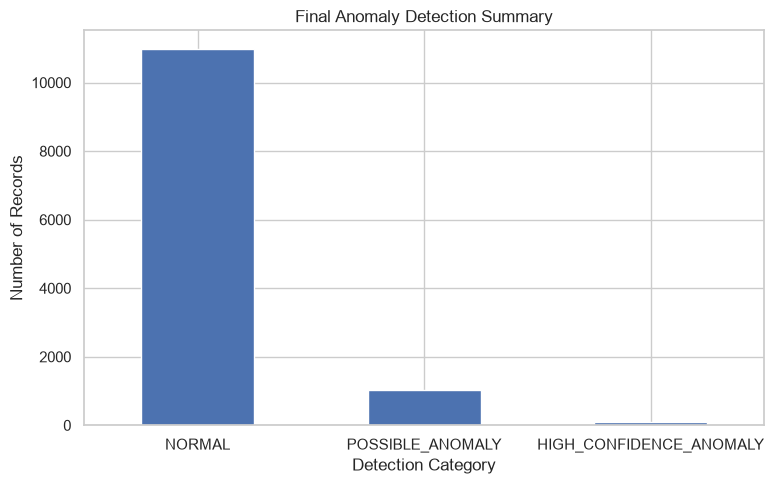

In [33]:
plt.figure(figsize=(8, 5))

severity_summary.set_index("severity")["count"].plot(kind="bar")

plt.xlabel("Detection Category")
plt.ylabel("Number of Records")
plt.title("Final Anomaly Detection Summary")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
model_comparison = pd.DataFrame({
    "Model": ["Isolation Forest", "Local Outlier Factor"],
    "Anomalies Detected": [
        (df["status"] == "ANOMALY").sum(),
        (df["lof_status"] == "ANOMALY").sum()
    ]
})

print("===== MODEL COMPARISON =====")
model_comparison

===== MODEL COMPARISON =====


,Model,Anomalies Detected
0,Isolation Forest,605
1,Local Outlier Factor,605


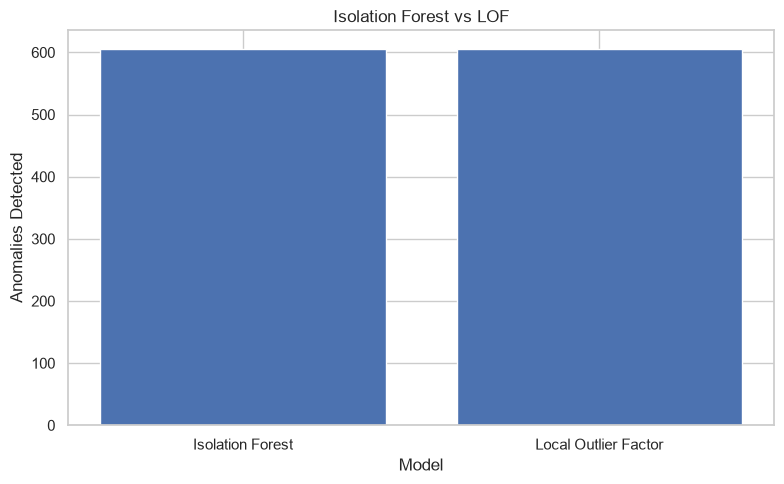

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["Anomalies Detected"]
)

plt.xlabel("Model")
plt.ylabel("Anomalies Detected")
plt.title("Isolation Forest vs LOF")
plt.tight_layout()
plt.show()

In [36]:
final_results = pd.read_csv("../results/predictions/final_anomaly_results.csv")

print("Final results loaded successfully!")
print("Rows:", len(final_results))
print("Columns:", len(final_results.columns))

final_results.head()

Final results loaded successfully!
Rows: 12096
Columns: 14


,timestamp,server_id,cpu_usage,memory_usage,disk_usage,network_traffic,response_time,request_rate,anomaly_score,anomaly,status,lof_prediction,lof_status,final_status
0,2014-02-14 14:27:00,SERVER-01,51.846,63.433712,0.1,0.239985,72.239873,96.050844,0.085659,1,NORMAL,1,NORMAL,NORMAL
1,2014-02-14 14:32:00,SERVER-01,44.508,60.856538,0.1,3.055105,62.801950,85.923800,0.096373,1,NORMAL,1,NORMAL,NORMAL
2,2014-02-14 14:37:00,SERVER-01,41.244,59.360727,0.1,0.274083,62.723795,79.731062,0.209150,1,NORMAL,1,NORMAL,NORMAL
3,2014-02-14 14:42:00,SERVER-01,48.568,62.804124,0.1,0.227875,54.152422,81.115477,0.169761,1,NORMAL,1,NORMAL,NORMAL
4,2014-02-14 14:47:00,SERVER-01,46.714,60.620752,0.1,0.234489,61.861019,84.759392,0.193611,1,NORMAL,1,NORMAL,NORMAL
